<a href="https://colab.research.google.com/github/EMatCM/AdminPanel/blob/main/notebooks/baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q torch torchvision pillow

import json, random, time
from pathlib import Path

import torch
import torch.nn as nn
from PIL import Image
from torchvision import datasets, models, transforms


In [2]:
SEMILLA = 42
TAM = 224
MEDIA, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CLASE_MALA = "rottenapples"
RUTA_DATOS = "/content/apples_dataset"
MODELO_PATH = Path("/content/modelo_manzana_baseline.pt")

def fijar_semilla(s=SEMILLA):
    random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
fijar_semilla()

In [3]:
!unzip -q apples_dataset.zip -d /content/apples_dataset/
!find /content -maxdepth 2 -type d -not -path "*/sample_data*" -not -path "*/.config*"

/content
/content/apples_dataset
/content/apples_dataset/test
/content/apples_dataset/train


In [4]:
def tf_eval():
    return transforms.Compose([
        transforms.Resize((TAM, TAM)),
        transforms.ToTensor(),
        transforms.Normalize(MEDIA, STD),
    ])

def tf_train():
    return tf_eval()

def crear_modelo(n_clases=2, congelar=True):
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    if congelar:
        for p in m.parameters():
            p.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, n_clases)
    return m

In [5]:
@torch.no_grad()
def evaluar_loader(modelo, loader, clases):
    modelo.eval()
    idx_mala = clases.index(CLASE_MALA)
    tp = fp = fn = tn = 0
    for x, y in loader:
        x, y = x.to(dev), y.to(dev)
        pred = modelo(x).argmax(1)
        for p, t in zip(pred.tolist(), y.tolist()):
            if p == idx_mala and t == idx_mala: tp += 1
            elif p == idx_mala and t != idx_mala: fp += 1
            elif p != idx_mala and t == idx_mala: fn += 1
            else: tn += 1
    total = tp + fp + fn + tn
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"accuracy": (tp + tn) / total if total else 0.0,
            "precision_mala": prec, "recall_mala": rec, "f1_mala": f1,
            "matriz_confusion": {"TP": tp, "FP": fp, "FN": fn, "TN": tn}, "n": total}

In [6]:
EPOCAS, BATCH, LR = 5, 32, 1e-3

ds_tr = datasets.ImageFolder(f"/content/apples_dataset/train", tf_train())
ds_va = datasets.ImageFolder(f"/content/apples_dataset/test", tf_eval())
clases = ds_tr.classes
assert CLASE_MALA in clases, f"Clases encontradas: {clases}"
print(f"Clases: {clases} | train={len(ds_tr)} val={len(ds_va)}")

dl_tr = torch.utils.data.DataLoader(ds_tr, batch_size=BATCH, shuffle=True, num_workers=2)
dl_va = torch.utils.data.DataLoader(ds_va, batch_size=BATCH, num_workers=2)

modelo = crear_modelo(len(clases)).to(dev)
opt = torch.optim.Adam(modelo.fc.parameters(), lr=LR)
perdida = nn.CrossEntropyLoss()

mejor_f1, t0 = -1.0, time.time()
for ep in range(1, EPOCAS + 1):
    modelo.train()
    total_loss = 0.0
    for x, y in dl_tr:
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad()
        loss = perdida(modelo(x), y)
        loss.backward()
        opt.step()
        total_loss += loss.item() * x.size(0)
    m = evaluar_loader(modelo, dl_va, clases)
    print(f"Época {ep}/{EPOCAS} | loss={total_loss/len(ds_tr):.4f} | "
          f"val acc={m['accuracy']:.3f} F1(mala)={m['f1_mala']:.3f} recall(mala)={m['recall_mala']:.3f}")
    if m["f1_mala"] >= mejor_f1:   # se elige con validación, nunca con test
        mejor_f1 = m["f1_mala"]
        torch.save({"state_dict": modelo.state_dict(), "clases": clases,
                    "epoca": ep, "lr": LR, "batch": BATCH}, MODELO_PATH)

print(f"Listo en {time.time()-t0:.1f}s | mejor F1 val = {mejor_f1:.3f}")

Clases: ['freshapples', 'rottenapples'] | train=4035 val=996
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 98.6MB/s]


Época 1/5 | loss=0.2319 | val acc=0.950 F1(mala)=0.960 recall(mala)=0.987
Época 2/5 | loss=0.1200 | val acc=0.978 F1(mala)=0.982 recall(mala)=0.977
Época 3/5 | loss=0.0993 | val acc=0.976 F1(mala)=0.980 recall(mala)=0.970
Época 4/5 | loss=0.0817 | val acc=0.976 F1(mala)=0.980 recall(mala)=0.965
Época 5/5 | loss=0.0724 | val acc=0.979 F1(mala)=0.982 recall(mala)=0.968
Listo en 2523.9s | mejor F1 val = 0.982


In [8]:
ck = torch.load(MODELO_PATH, map_location=dev)
modelo = crear_modelo(len(ck["clases"]), congelar=False)
modelo.load_state_dict(ck["state_dict"])
modelo = modelo.to(dev).eval()
clases = ck["clases"]

ds_te = datasets.ImageFolder(f"/content/apples_dataset/test", tf_eval())
dl_te = torch.utils.data.DataLoader(ds_te, batch_size=BATCH, num_workers=2)
res = evaluar_loader(modelo, dl_te, clases)
print(json.dumps(res, indent=2, ensure_ascii=False))

Path("/content/resultados_test_baseline.json").write_text(
    json.dumps(res, indent=2, ensure_ascii=False))

{
  "accuracy": 0.9789156626506024,
  "precision_mala": 0.9965753424657534,
  "recall_mala": 0.9683860232945092,
  "f1_mala": 0.9822784810126582,
  "matriz_confusion": {
    "TP": 582,
    "FP": 2,
    "FN": 19,
    "TN": 393
  },
  "n": 996
}


243

Saving istockphoto-157309232-612x612.jpg to istockphoto-157309232-612x612.jpg


**Manzana:** ROTTENAPPLES (confianza 99.6%)

**Probabilidades:** freshapples: 0.4%, rottenapples: 99.6%

**Inferencia:** 160.7 ms

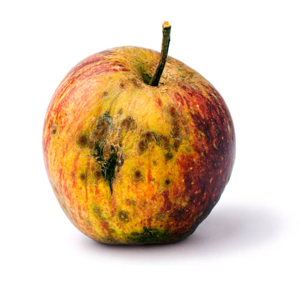

In [9]:
@torch.no_grad()
def predecir_imagen(ruta, umbral_mala=0.5):
    img = Image.open(ruta).convert("RGB")
    x = tf_eval()(img).unsqueeze(0).to(dev)
    t0 = time.time()
    prob = torch.softmax(modelo(x), dim=1)[0].cpu()
    ms = (time.time() - t0) * 1000
    p = {c: float(prob[i]) for i, c in enumerate(clases)}
    etiqueta = CLASE_MALA if p[CLASE_MALA] >= umbral_mala else next(c for c in clases if c != CLASE_MALA)
    return etiqueta, p[etiqueta], p, ms

from google.colab import files
# sube una imagen
subida = files.upload()
ruta = list(subida.keys())[0]

from IPython.core.display import Markdown, display

etiqueta, conf, p, ms = predecir_imagen(ruta, umbral_mala=0.5)
display(Markdown(f"**Manzana:** {etiqueta.upper()} (confianza {conf:.1%})"))

probs_texto = ", ".join(f"{k}: {v:.1%}" for k, v in p.items())
display(Markdown(f"**Probabilidades:** {probs_texto}"))

display(Markdown(f"**Inferencia:** {ms:.1f} ms"))
if conf < 0.6:
    print("Aviso: confianza baja, resultado incierto.")

from IPython.display import display
display(Image.open(ruta).resize((300, 300)))

In [10]:
%cd /content/repositorio
!mkdir -p notebooks modelos resultados docs
!cp /content/modelo_manzana_baseline.pt modelos/baseline_v1.pt
!cp /content/resultados_test_baseline.json resultados/baseline_test.json


/content/repositorio


In [11]:
%%writefile requirements.txt
torch
torchvision
pillow

Writing requirements.txt


In [12]:
%%writefile .gitignore
apples_dataset/
*.zip
sample_data/
__pycache__/
.ipynb_checkpoints/

Writing .gitignore


In [13]:
%%writefile README.md
# Clasificación de manzanas (buena/mala) - Baseline

Baseline: ResNet18 preentrenada (ImageNet), backbone congelado, solo se entrena la capa final.
Sin aumento de datos, umbral 0.5, 5 épocas.

## Datos
Dataset de manzanas freshapples/rottenapples. Origen y licencia: (completar).
El dataset no se incluye en el repositorio.

## Uso
pip install -r requirements.txt
Ver notebooks/baseline.ipynb

Writing README.md
